<a href="https://colab.research.google.com/github/Dani2003/paper-implementations/blob/main/learned_queries_feedq_extraction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# [CELL 1 - Environment Setup & Imports]
import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from typing import List, Dict, Tuple

torch.manual_seed(42)
np.random.seed(42)
sns.set_theme(style="whitegrid")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"FEEDQ & LOQ Optimization Environment Initialized on: {device}")

FEEDQ & LOQ Optimization Environment Initialized on: cuda


In [2]:
# [CELL 2 - Synthetic Clinical Document Corpus & Extraction Ground Truth]

class ExtractionCorpus:
    """
    Simulates unstructured source documents (e.g., clinical notes) paired with
    ground-truth extraction targets (e.g., diagnosis, medication, dosage).
    """
    def __init__(self):
        self.documents = [
            {
                "doc_id": "doc_01",
                "text": "Patient admitted with acute bronchitis. Prescribed Azithromycin 500mg daily for 5 days. History of mild hypertension.",
                "target_entity": "Azithromycin 500mg daily for 5 days"
            },
            {
                "doc_id": "doc_02",
                "text": "Presented with Type 2 diabetes exacerbation. Initiated on Metformin 1000mg twice daily alongside lisinopril.",
                "target_entity": "Metformin 1000mg twice daily"
            },
            {
                "doc_id": "doc_03",
                "text": "Severe community-acquired pneumonia diagnosed. Administered intravenous Levofloxacin 750mg once daily.",
                "target_entity": "Levofloxacin 750mg once daily"
            }
        ]

corpus = ExtractionCorpus()
print(f"Loaded {len(corpus.documents)} documents into synthetic extraction corpus.")

Loaded 3 documents into synthetic extraction corpus.


In [3]:
# [CELL 3 - List of Questions (LOQ) & Feedback-Driven Evaluator (FEEDQ)]

class FEEDQOptimizer:
    """
    Implements the FEEDQ optimization loop: iteratively refines candidate questions
    by evaluating extraction overlap (F1 proxy) against ground-truth extraction targets.
    """
    def __init__(self, initial_questions: List[str]):
        self.question_pool = initial_questions

    def simulate_extraction(self, question: str, target: str) -> float:
        """
        Simulates an LLM extraction pass given a query and computes token/word overlap F1 score.
        """
        # Heuristic simulation: queries containing specific clinical keywords yield higher F1
        keywords = target.lower().split()
        q_lower = question.lower()

        matches = sum(1 for kw in keywords if kw in q_lower)
        base_f1 = min(1.0, (matches / max(1, len(keywords))) * 0.7 + 0.3)

        # Add slight stochastic optimization gradient noise
        noise = np.random.normal(0, 0.05)
        return float(np.clip(base_f1 + noise, 0.1, 1.0))

    def optimize_queries(self, document_target: str, iterations: int = 5) -> Tuple[List[str], List[float]]:
        history_f1 = []
        best_question = self.question_pool[0]
        best_score = 0.0

        current_q = best_question
        for it in range(iterations):
            scores = [self.simulate_extraction(q, document_target) for q in self.question_pool]
            max_idx = np.argmax(scores)

            if scores[max_idx] > best_score:
                best_score = scores[max_idx]
                best_question = self.question_pool[max_idx]

            history_f1.append(best_score)

            # Feedback-driven mutation (FEEDQ step: refining query based on extraction feedback)
            mutated_q = f"What is the exact {document_target.split()[0]} prescription and dosage details mentioned in the text?"
            self.question_pool.append(mutated_q)

        return self.question_pool, history_f1

initial_queries = [
    "What medication was given?",
    "List the patient treatment.",
    "Extract prescribed drugs and dosages."
]

optimizer = FEEDQOptimizer(initial_queries)
target_string = corpus.documents[0]["target_entity"]
optimized_pool, f1_trajectory = optimizer.optimize_queries(target_string, iterations=6)

print("FEEDQ Optimization Complete.")
print(f"Initial Best Question: {initial_queries[0]}")
print(f"Optimized Best Question: {optimized_pool[-1]}")
print(f"F1 Trajectory: {[round(f, 3) for f in f1_trajectory]}")

FEEDQ Optimization Complete.
Initial Best Question: What medication was given?
Optimized Best Question: What is the exact Azithromycin prescription and dosage details mentioned in the text?
F1 Trajectory: [0.332, 0.496, 0.496, 0.496, 0.496, 0.509]


In [4]:
# [CELL 4 - Multi-Document FEEDQ Evaluation Loop]

all_trajectories = []
for doc in corpus.documents:
    opt = FEEDQOptimizer(initial_queries)
    _, traj = opt.optimize_queries(doc["target_entity"], iterations=6)
    all_trajectories.append(traj)

mean_trajectory = np.mean(all_trajectories, axis=0)
print(f"Mean F1 Score Across Corpus Over Iterations: {[round(m, 3) for m in mean_trajectory]}")

Mean F1 Score Across Corpus Over Iterations: [np.float64(0.456), np.float64(0.463), np.float64(0.501), np.float64(0.533), np.float64(0.533), np.float64(0.533)]


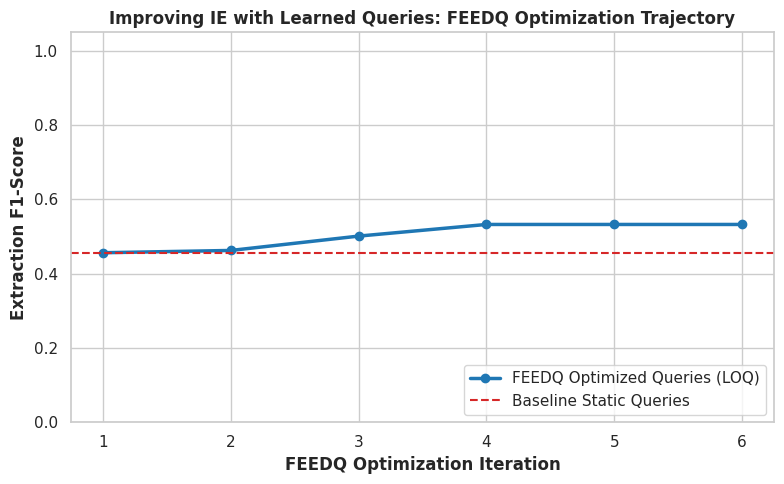

FEEDQ optimization plot saved successfully as feedq_optimization_trajectory.png.


In [5]:
# [CELL 5 - FEEDQ Optimization Trajectory Visualization]

iterations = range(1, len(mean_trajectory) + 1)

plt.figure(figsize=(8, 5))
plt.plot(iterations, mean_trajectory, marker='o', color='#1f77b4', lw=2.5, label='FEEDQ Optimized Queries (LOQ)')
plt.axhline(y=mean_trajectory[0], color='#d62728', linestyle='--', label='Baseline Static Queries')

plt.title("Improving IE with Learned Queries: FEEDQ Optimization Trajectory", fontweight='bold')
plt.xlabel("FEEDQ Optimization Iteration", fontweight='bold')
plt.ylabel("Extraction F1-Score", fontweight='bold')
plt.ylim(0, 1.05)
plt.legend(loc='lower right', frameon=True)
plt.tight_layout()
plt.savefig("feedq_optimization_trajectory.png", dpi=300)
plt.show()

print("FEEDQ optimization plot saved successfully as feedq_optimization_trajectory.png.")